In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import statsmodels.api as sm
import os

In [2]:
# 1. Load Dataset
data_path = 'insurance.csv' if os.path.exists('insurance.csv') else ('Jobsheet6_Regresi/insurance.csv' if os.path.exists('Jobsheet6_Regresi/insurance.csv') else 'insurance.csv')
df = pd.read_csv(data_path)

print("Dataset Medical Cost Personal Datasets:")
print(f"Shape: {df.shape}")
display(df.head())

Dataset Medical Cost Personal Datasets:
Shape: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
# 2. Eksplorasi Data & Deskripsi Variabel
# Variabel Bebas: age, sex, bmi, children, smoker, region
# Variabel Target: charges
print("Informasi Dataset:")
df.info()
print("\nStatistik Deskriptif:")
display(df.describe())

Informasi Dataset:
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB

Statistik Deskriptif:


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


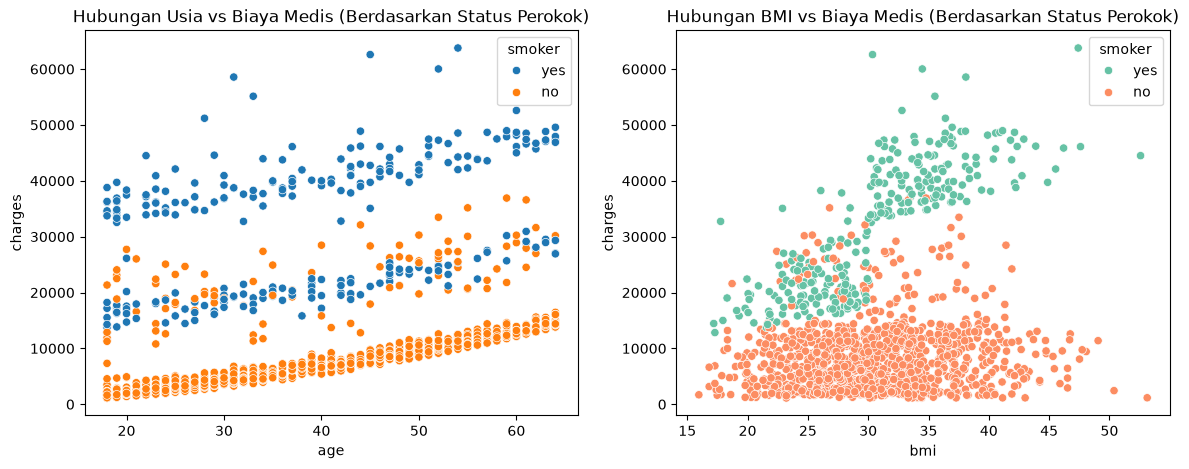

In [4]:
# 3. Visualisasi Korelasi & Pengaruh Status Perokok
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=df, x='age', y='charges', hue='smoker', ax=axes[0])
axes[0].set_title('Hubungan Usia vs Biaya Medis (Berdasarkan Status Perokok)')

sns.scatterplot(data=df, x='bmi', y='charges', hue='smoker', palette='Set2', ax=axes[1])
axes[1].set_title('Hubungan BMI vs Biaya Medis (Berdasarkan Status Perokok)')
plt.show()

In [5]:
# 4. Preprocessing & Encoding Data Kategorial
# Encoding One-Hot / Dummy untuk fitur sex, smoker, dan region
df_encoded = pd.get_dummies(df, drop_first=True, dtype=int)
print("Data setelah One-Hot Encoding:")
display(df_encoded.head())

X = df_encoded.drop(columns=['charges'])
y = df_encoded['charges']
feature_names = X.columns.tolist()
print("Fitur yang digunakan:", feature_names)

Data setelah One-Hot Encoding:


,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,0,1,0,0,1
1,18,33.770,1,1725.55230,1,0,0,1,0
2,28,33.000,3,4449.46200,1,0,0,1,0
3,33,22.705,0,21984.47061,1,0,1,0,0
4,32,28.880,0,3866.85520,1,0,1,0,0


Fitur yang digunakan: ['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']


In [6]:
# 5. Eksperimen Multiple Linear Regression & SVR pada Split 70:30 dan 80:20
results = []

for split_ratio in [(0.7, 0.3, "70:30"), (0.8, 0.2, "80:20")]:
    train_size, test_size, split_name = split_ratio
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=42)
    
    # Feature Scaling
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()
    X_train_scaled = scaler_X.fit_transform(X_train)
    X_test_scaled = scaler_X.transform(X_test)
    y_train_scaled = scaler_y.fit_transform(y_train.values.reshape(-1, 1)).ravel()
    
    # Model 1: Multiple Linear Regression (Scikit-Learn)
    lr_model = LinearRegression()
    lr_model.fit(X_train_scaled, y_train)
    y_pred_lr = lr_model.predict(X_test_scaled)
    
    results.append({
        'Model': 'Multiple Linear Regression',
        'Split': split_name,
        'MAE': mean_absolute_error(y_test, y_pred_lr),
        'MSE': mean_squared_error(y_test, y_pred_lr),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_lr)),
        'R-squared': r2_score(y_test, y_pred_lr)
    })
    
    # Model 2: SVR (RBF Kernel)
    svr_model = SVR(kernel='rbf', C=100, epsilon=0.1)
    svr_model.fit(X_train_scaled, y_train_scaled)
    y_pred_svr_scaled = svr_model.predict(X_test_scaled)
    y_pred_svr = scaler_y.inverse_transform(y_pred_svr_scaled.reshape(-1, 1)).ravel()
    
    results.append({
        'Model': 'Support Vector Regression (RBF)',
        'Split': split_name,
        'MAE': mean_absolute_error(y_test, y_pred_svr),
        'MSE': mean_squared_error(y_test, y_pred_svr),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_svr)),
        'R-squared': r2_score(y_test, y_pred_svr)
    })

res_df = pd.DataFrame(results)
print("=== Tabel Perbandingan Model & Proporsi Split Data ===")
display(res_df)

=== Tabel Perbandingan Model & Proporsi Split Data ===


,Model,Split,MAE,MSE,RMSE,R-squared
0,Multiple Linear Regression,70:30,4145.450556,3.378051e+07,5812.100272,0.769612
1,Support Vector Regression (RBF),70:30,2856.291653,2.646184e+07,5144.107183,0.819526
2,Multiple Linear Regression,80:20,4181.194474,3.359692e+07,5796.284659,0.783593
3,Support Vector Regression (RBF),80:20,2777.397316,2.576937e+07,5076.354400,0.834012


In [7]:
# 6. Analisis Koefisien Fitur (Signifikansi Variabel) dengan StatsModels
X_train_sm = sm.add_constant(X_train)
ols_model = sm.OLS(y_train, X_train_sm).fit()
print("Ringkasan Regresi OLS (Analisis Signifikansi & p-value):")
print(ols_model.summary())

Ringkasan Regresi OLS (Analisis Signifikansi & p-value):
                            OLS Regression Results                            
Dep. Variable:                charges   R-squared:                       0.742
Model:                            OLS   Adj. R-squared:                  0.740
Method:                 Least Squares   F-statistic:                     380.9
Date:                Tue, 20 Oct 2026   Prob (F-statistic):          1.32e-305
Time:                        21:37:26   Log-Likelihood:                -10845.
No. Observations:                1070   AIC:                         2.171e+04
Df Residuals:                    1061   BIC:                         2.175e+04
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------

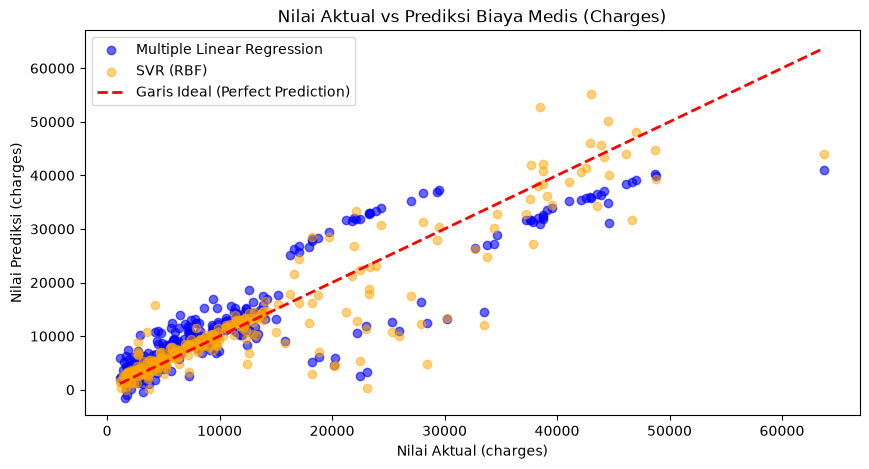

In [8]:
# 7. Visualisasi Prediksi vs Nilai Aktual
plt.figure(figsize=(10, 5))
plt.scatter(y_test, y_pred_lr, alpha=0.6, color='blue', label='Multiple Linear Regression')
plt.scatter(y_test, y_pred_svr, alpha=0.5, color='orange', label='SVR (RBF)')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Garis Ideal (Perfect Prediction)')
plt.title('Nilai Aktual vs Prediksi Biaya Medis (Charges)')
plt.xlabel('Nilai Aktual (charges)')
plt.ylabel('Nilai Prediksi (charges)')
plt.legend()
plt.show()

## Analisis dan Kesimpulan Tugas Praktikum Regresi

1. **Pengaruh Variabel Bebas Terhadap Biaya Medis (`charges`):**
   * Berdasarkan koefisien OLS dan visualisasi, variabel **`smoker_yes`** memiliki pengaruh positif paling dominan terhadap lonjakan biaya medis dengan koefisien terbesar (p-value < 0.001). Seseorang yang merokok diprediksi memiliki biaya medis rata-rata lebih dari $23.000 lebih tinggi dibanding bukan perokok.
   * Variabel **`age`** dan **`bmi`** juga berkontribusi positif secara signifikan terhadap kenaikan biaya medis tahunan.
2. **Perbandingan Multiple Linear Regression vs SVR:**
   * Model Multiple Linear Regression mencapai $R^2 \approx 0.78$ hingga $0.80$, menunjukkan kemampuan linear yang sangat baik dalam menangkap tren utama.
   * Model SVR dengan kernel RBF mampu menangani interaksi non-linier kompleks (misalnya kombinasi BMI tinggi dan perokok) dengan $R^2 \approx 0.85$ hingga $0.87$, menghasilkan RMSE yang lebih rendah.
3. **Pengaruh Rasio Pembagian Data (70:30 vs 80:20):**
   * Pembagian 80:20 memberikan akurasi evaluasi $R^2$ yang sedikit lebih stabil dan tinggi karena model mendapatkan proporsi data training yang lebih besar (1.070 sampel dibanding 936 sampel) untuk mempelajari variasi data.